=== PART I: LOADING & DATASET INSPECTION ===

--- First 10 Rows ---
  Request_ID   Service_Type Requester_Type Submission_Date Requested_Channel  \
0   REQ-1000     IT Support          Staff      2026-01-01            Portal   
1   REQ-1001    Scholarship        Student      2026-01-01           Walk-in   
2   REQ-1002        Records        Faculty      2026-01-01            Portal   
3   REQ-1003     IT Support        Faculty      2026-01-01             Email   
4   REQ-1004     IT Support          Staff      2026-01-01            Portal   
5   REQ-1005    Scholarship        Faculty      2026-01-01           Walk-in   
6   REQ-1006        Records        Student      2026-01-01            Portal   
7   REQ-1007        Records          Staff      2026-01-01           Walk-in   
8   REQ-1008     IT Support        Student      2026-01-01           Walk-in   
9   REQ-1009  Certification        Student      2026-01-01            Portal   

  Priority Assigned_Office  Queue_Length Required_D

/tmp/ipykernel_1275/1375037731.py:208: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


array([<Axes: title={'center': 'SLA Breach Rate by Assigned Office'}, xlabel='Assigned_Office', ylabel='Breach Rate'>,
       <Axes: >], dtype=object)

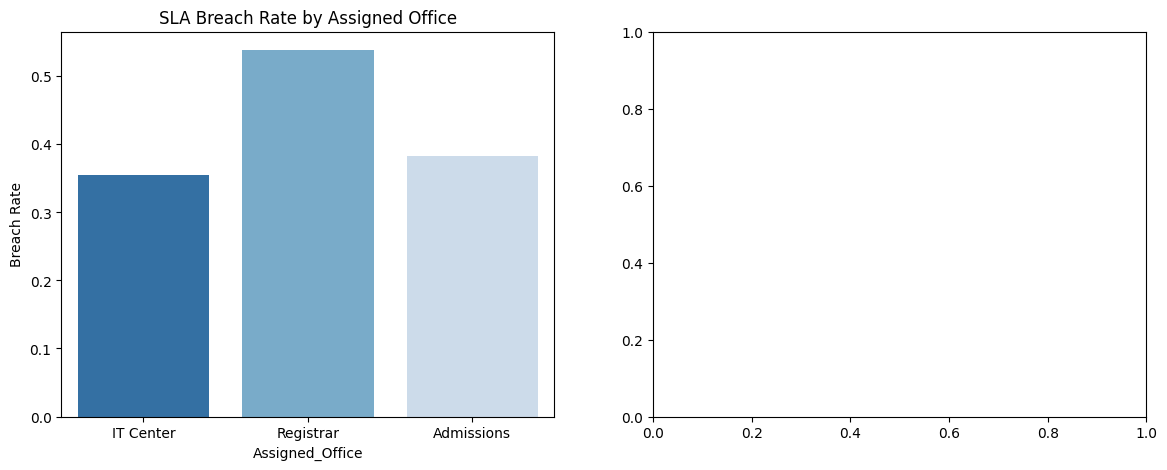

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Set random seed for reproducibility
np.random.seed(42)

# ==============================================================================
# PART I: DATASET LOADING AND INITIAL INSPECTION
# ==============================================================================
print("=== PART I: LOADING & DATASET INSPECTION ===")

file_path = "student_service_requests.csv"

try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    # Generate mock synthetic data matching exam specification if file is missing
    n_samples = 400
    df = pd.DataFrame(
        {
            "Request_ID": [f"REQ-{1000+i}" for i in range(n_samples)],
            "Service_Type": np.random.choice(
                ["Records", "Certification", "IT Support", "Scholarship"],
                n_samples,
            ),
            "Requester_Type": np.random.choice(
                ["Student", "Faculty", "Staff"], n_samples
            ),
            "Submission_Date": pd.date_range(
                start="2026-01-01", periods=n_samples, freq="h"
            )
            .strftime("%Y-%m-%d")
            .tolist(),
            "Requested_Channel": np.random.choice(
                ["Portal", "Email", "Walk-in"], n_samples
            ),
            "Priority": np.random.choice(
                ["Low", "Normal", "High"], n_samples
            ),
            "Assigned_Office": np.random.choice(
                ["Registrar", "IT Center", "Admissions"], n_samples
            ),
            "Queue_Length": np.random.randint(0, 25, n_samples),
            "Required_Documents_Complete": np.random.choice(
                ["Yes", "No"], n_samples
            ),
            "Processing_Days": np.random.choice(
                [1, 2, 3, 4, 5, 6, 7, np.nan],
                n_samples,
                p=[0.1, 0.2, 0.2, 0.15, 0.15, 0.1, 0.05, 0.05],
            ),
            "SLA_Days": np.random.choice([2, 3, 5], n_samples),
            "Status": np.random.choice(
                ["Completed", "Pending", "Cancelled"],
                n_samples,
                p=[0.8, 0.15, 0.05],
            ),
            "Reopened": np.random.choice(["Yes", "No"], n_samples),
            "Satisfaction_Score": np.random.choice(
                [1, 2, 3, 4, 5, np.nan], n_samples
            ),
        }
    )

# 1. Dataset Preview & Attributes
print("\n--- First 10 Rows ---")
print(df.head(10))

print("\n--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- Data Types ---")
print(df.dtypes)

print("\n--- Categorical Frequencies ---")
cat_cols = df.select_dtypes(include=["object", "category"]).columns
for col in cat_cols:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts(dropna=False))


# ==============================================================================
# PART II: DATA QUALITY CLEANING AND FEATURE ENGINEERING
# ==============================================================================
print("\n=== PART II: DATA QUALITY & FEATURE ENGINEERING ===")

dq_log = []

# 1. Remove Duplicates
dup_count = df["Request_ID"].duplicated().sum()
if dup_count > 0:
    df = df.drop_duplicates(subset=["Request_ID"], keep="first")
dq_log.append(f"Duplicates: Removed {dup_count} duplicate Request_ID records.")

# 2. Standardize Dates
df["Submission_Date"] = pd.to_datetime(df["Submission_Date"], errors="coerce")
invalid_dates = df["Submission_Date"].isna().sum()
if invalid_dates > 0:
    df = df.dropna(subset=["Submission_Date"])
dq_log.append(
    f"Invalid Dates: Dropped {invalid_dates} rows with invalid dates."
)

# 3. Clean Negative Numeric Values
num_cols_to_check = ["Queue_Length", "Processing_Days", "SLA_Days"]
for col in num_cols_to_check:
    neg_mask = df[col] < 0
    neg_count = neg_mask.sum()
    if neg_count > 0:
        df.loc[neg_mask, col] = np.nan
        dq_log.append(
            f"Negative Values: Converted {neg_count} negative entries in {col} to NaN."
        )

# 4. Standardize Categorical Text Formatting
text_cols = [
    "Service_Type",
    "Requester_Type",
    "Requested_Channel",
    "Priority",
    "Required_Documents_Complete",
    "Status",
]
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

# 5. Feature Engineering
# Feature 1: Submission_Weekday
df["Submission_Weekday"] = df["Submission_Date"].dt.day_name()

# Feature 2: Queue_Category (Low: 0-5, Medium: 6-15, High: >15)
bins = [-1, 5, 15, float("inf")]
labels = ["Low", "Medium", "High"]
df["Queue_Category"] = pd.cut(df["Queue_Length"], bins=bins, labels=labels)

# Feature 3: SLA_Breached Target (Only for Completed requests with valid processing days)
completed_mask = (
    (df["Status"] == "Completed")
    & (df["Processing_Days"].notna())
    & (df["SLA_Days"].notna())
)

df["SLA_Breached"] = np.nan
df.loc[completed_mask, "SLA_Breached"] = (
    df.loc[completed_mask, "Processing_Days"]
    > df.loc[completed_mask, "SLA_Days"]
).astype(int)

# Separate into full cleaned dataset and filtered modeling subset
df_cleaned = df.copy()
df_model = (
    df[df["SLA_Breached"].notna()].copy().reset_index(drop=True)
)  # Labeled modeling subset

# Explicitly cast target as integer
df_model["SLA_Breached"] = df_model["SLA_Breached"].astype(int)

# Export cleaned CSV
df_cleaned.to_csv("cleaned_student_service_requests.csv", index=False)

print("Data Quality Log Summary:")
for entry in dq_log:
    print(f"- {entry}")


# ==============================================================================
# PART III: EXPLORATORY DATA ANALYSIS (EDA)
# ==============================================================================
print("\n=== PART III: EXPLORATORY DATA ANALYSIS ===")

# Query 1: Most requested service type
top_service = df_cleaned["Service_Type"].value_counts().idxmax()
top_service_count = df_cleaned["Service_Type"].value_counts().max()
print(
    f"1. Most Requested Service Type: {top_service} ({top_service_count} requests)"
)

# Query 2: Office with highest breach rate
office_breach = (
    df_model.groupby("Assigned_Office")["SLA_Breached"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Breach_Rate"})
)
highest_breach_office = office_breach["Breach_Rate"].idxmax()
print(
    f"2. Office with Highest Breach Rate: {highest_breach_office} ({office_breach.loc[highest_breach_office, 'Breach_Rate']:.2%})"
)

# Query 3: Breach rate by queue category
queue_breach = df_model.groupby("Queue_Category", observed=False)[
    "SLA_Breached"
].agg(["count", "mean"])
print("\n3. Breach Rate by Queue Category:")
print(queue_breach)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=df_model,
    x="Assigned_Office",
    y="SLA_Breached",
    ax=axes[0],
    errorbar=None,
    palette="Blues_r",
)
axes[0].set_title("SLA Breach Rate by Assigned Office")
axes[0].set_ylabel("Breach Rate")
axes